# 05 — US AlphaEarth baseline (locked LORO + macro-F1)

**Protocol B.** Evaluate **AlphaEarth-only** building-type classification on the US dataset from
notebook 04 under a **locked evaluation protocol**. This is a lower-modality baseline on
high-precision OSM/Overture labels — **not** a modality-matched comparison to multi-modal
SOTA (street-view / VHR / HeteroGNN ~86–96% accuracy).

**Primary metric:** macro-F1 under **leave-one-region-out (LORO)**.  
**Secondary:** pooled stratified holdout (optimistic upper bound); per-class F1; confusion matrix.

**Data.** `outputs/sota_building_type/dataset.parquet` (10 metros × 10 labels × 64-D centroid embeddings).

**Models.** Logistic regression and HistGradientBoosting on standardized `A00…A63`.


## Claim language (locked)

| Allowed | Not allowed |
|---|---|
| “AlphaEarth + simple classifier on OSM high-precision 10-class GT” | “Matches / beats SOTA 86–96%” |
| LORO macro-F1 / accuracy / per-class F1 | Comparing modalities as if equal |
| Within-dataset ablations later (+SVI/+VHR) | Citing HeteroGNN numbers as peer scores without matched cities/splits/modalities |

Reference SOTA for later Protocol A only: Liang et al., ISPRS 2026 (HeteroGNN) —
Amsterdam / Washington D.C. / Berlin; mean F1 0.70–0.73.


In [13]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

ROOT = Path(".").resolve()
if not (ROOT / "requirements.txt").exists() and (ROOT.parent / "requirements.txt").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "outputs" / "sota_building_type" / "dataset.parquet"
OUT_DIR = ROOT / "outputs" / "us_loro_baseline"
OUT_DIR.mkdir(parents=True, exist_ok=True)

BANDS = [f"A{i:02d}" for i in range(64)]
RANDOM_STATE = 42
HOLDOUT_FRACTION = 0.2

LABEL_ORDER = [
    "single_family",
    "multi_family",
    "retail",
    "hotel",
    "office",
    "industrial",
    "education",
    "medical",
    "religious",
    "civic",
]

print("ROOT:", ROOT)
print("Data:", DATA_PATH)
print("Outputs:", OUT_DIR)


ROOT: /data/users/kv133/Alpha-Earth-Embeddings-Research
Data: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/sota_building_type/dataset.parquet
Outputs: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline


## 1. Load locked dataset

Require full 10-class coverage, no null embedding bands, and unique building ids.


In [14]:
assert DATA_PATH.exists(), f"Missing {DATA_PATH} — run notebook 04 first."

df = pd.read_parquet(DATA_PATH)
df["id"] = df["id"].astype(str)
df["label"] = pd.Categorical(df["label"], categories=LABEL_ORDER, ordered=True)

assert df["id"].is_unique
assert df[BANDS].notna().all().all()
assert set(df["label"].dropna().unique()) == set(LABEL_ORDER)
assert df.groupby("region")["label"].nunique().min() == len(LABEL_ORDER)

# Fixed integer codes matching LABEL_ORDER (do NOT use LabelEncoder — it sorts alphabetically).
label_to_y = {lab: i for i, lab in enumerate(LABEL_ORDER)}
df["y"] = df["label"].astype(str).map(label_to_y).astype(int)
assert df["y"].between(0, len(LABEL_ORDER) - 1).all()

X = df[BANDS].to_numpy(dtype=np.float64)
y = df["y"].to_numpy(dtype=int)
regions = df["region"].to_numpy()
region_list = sorted(df["region"].unique())

print(f"n={len(df):,} · regions={len(region_list)} · classes={len(LABEL_ORDER)}")
print(df["label"].value_counts().reindex(LABEL_ORDER))
print(df.groupby("region").size().rename("n"))


n=11,280 · regions=10 · classes=10
label
single_family    1987
multi_family     1102
retail           1616
hotel             539
office            756
industrial       1287
education        1840
medical           594
religious         802
civic             757
Name: count, dtype: int64
region
Atlanta_SE    1018
Boston_NE     1370
Chicago_MW    1321
Denver_W      1126
Houston_S     1171
LA_W          1027
NYC_NE        1327
Phoenix_SW    1080
SF_W           805
Seattle_NW    1035
Name: n, dtype: int64


## 2. Locked split protocol

1. **Pooled stratified holdout** — 80/20 by `label` (same seed always). Written to
   `split_pooled ∈ {train, test}`.
2. **Leave-one-region-out** — for each metro \(R\): train on all \(\neq R\), test on \(R\).
   Primary reporting metric is **macro-F1** on each holdout (and the mean across regions).

Random `split_seed` from notebook 04 is **not** used as an evaluation split.


In [15]:
idx = np.arange(len(df))
idx_tr, idx_te = train_test_split(
    idx,
    test_size=HOLDOUT_FRACTION,
    stratify=y,
    random_state=RANDOM_STATE,
)

split_pooled = np.full(len(df), "train", dtype=object)
split_pooled[idx_te] = "test"
df["split_pooled"] = split_pooled

# Persist locked assignments for later ablations (+SVI / +VHR) on the same rows
splits_path = OUT_DIR / "locked_splits.parquet"
df[["id", "region", "label", "y", "split_pooled"]].to_parquet(splits_path, index=False)
print("Wrote", splits_path)
print(df["split_pooled"].value_counts())
print("Test label mix:\n", df.loc[df["split_pooled"] == "test", "label"].value_counts().reindex(LABEL_ORDER))


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/locked_splits.parquet
split_pooled
train    9024
test     2256
Name: count, dtype: int64
Test label mix:
 label
single_family    397
multi_family     221
retail           323
hotel            108
office           151
industrial       257
education        368
medical          119
religious        160
civic            152
Name: count, dtype: int64


## 3. Model zoo (AlphaEarth-only)

Both models use `class_weight` / imbalance-aware defaults where available.
Features are always the same 64-D annual centroid embeddings.


In [16]:
def make_lr() -> Pipeline:
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "clf",
                LogisticRegression(
                    max_iter=4000,
                    class_weight="balanced",
                    multi_class="multinomial",
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
            ),
        ]
    )


def make_hgb() -> HistGradientBoostingClassifier:
    # HGB has no class_weight; use balanced sample weights at fit time.
    return HistGradientBoostingClassifier(
        max_depth=6,
        learning_rate=0.08,
        max_iter=300,
        random_state=RANDOM_STATE,
    )


def balanced_sample_weight(y_fit: np.ndarray) -> np.ndarray:
    _, counts = np.unique(y_fit, return_counts=True)
    n = len(y_fit)
    k = len(counts)
    inv = {c: n / (k * cnt) for c, cnt in zip(*np.unique(y_fit, return_counts=True))}
    return np.array([inv[yi] for yi in y_fit], dtype=np.float64)


def fit_predict(model_name: str, X_tr, y_tr, X_te):
    if model_name == "logreg":
        model = make_lr()
        model.fit(X_tr, y_tr)
        pred = model.predict(X_te)
        return model, pred
    if model_name == "hgb":
        model = make_hgb()
        model.fit(X_tr, y_tr, sample_weight=balanced_sample_weight(y_tr))
        pred = model.predict(X_te)
        return model, pred
    raise ValueError(model_name)


MODELS = ["logreg", "hgb"]
print("Models:", MODELS)


Models: ['logreg', 'hgb']


## 4. Pooled stratified holdout (secondary)


In [17]:
pooled_rows = []
pooled_preds = {}

for name in MODELS:
    _, pred = fit_predict(name, X[idx_tr], y[idx_tr], X[idx_te])
    pooled_preds[name] = pred
    pooled_rows.append(
        {
            "protocol": "pooled_holdout",
            "model": name,
            "n_train": int(len(idx_tr)),
            "n_test": int(len(idx_te)),
            "accuracy": float(accuracy_score(y[idx_te], pred)),
            "f1_macro": float(f1_score(y[idx_te], pred, average="macro", zero_division=0)),
            "f1_weighted": float(f1_score(y[idx_te], pred, average="weighted", zero_division=0)),
        }
    )
    print("\n=== Pooled ·", name, "===")
    print(
        classification_report(
            y[idx_te],
            pred,
            labels=list(range(len(LABEL_ORDER))),
            target_names=LABEL_ORDER,
            digits=3,
            zero_division=0,
        )
    )

pooled = pd.DataFrame(pooled_rows)
pooled



=== Pooled · logreg ===
               precision    recall  f1-score   support

single_family      0.656     0.693     0.674       397
 multi_family      0.246     0.213     0.228       221
       retail      0.313     0.207     0.250       323
        hotel      0.205     0.407     0.272       108
       office      0.269     0.351     0.305       151
   industrial      0.528     0.634     0.576       257
    education      0.546     0.272     0.363       368
      medical      0.266     0.462     0.337       119
    religious      0.218     0.231     0.224       160
        civic      0.245     0.243     0.244       152

     accuracy                          0.389      2256
    macro avg      0.349     0.371     0.347      2256
 weighted avg      0.407     0.389     0.385      2256


=== Pooled · hgb ===
               precision    recall  f1-score   support

single_family      0.675     0.821     0.741       397
 multi_family      0.348     0.290     0.316       221
       retail 

,protocol,model,n_train,n_test,accuracy,f1_macro,f1_weighted
0,pooled_holdout,logreg,9024,2256,0.389,0.347,0.385
1,pooled_holdout,hgb,9024,2256,0.463,0.404,0.450


## 5. Leave-one-region-out (primary)

For each holdout metro, train on the other nine. Aggregate **mean ± std macro-F1** across
regions. Also store out-of-fold predictions for a pooled LORO confusion matrix.


In [18]:
loro_rows = []
oof = {name: np.full(len(df), -1, dtype=int) for name in MODELS}

for holdout in region_list:
    mask_te = regions == holdout
    mask_tr = ~mask_te
    n_te = int(mask_te.sum())
    n_tr = int(mask_tr.sum())
    # Every region has all 10 labels in this dataset; still guard.
    if n_te < 50 or n_tr < 200:
        print(f"Skip {holdout}: n_te={n_te} n_tr={n_tr}")
        continue
    if len(np.unique(y[mask_te])) < len(LABEL_ORDER):
        print(f"Warn {holdout}: missing classes in test")

    for name in MODELS:
        _, pred = fit_predict(name, X[mask_tr], y[mask_tr], X[mask_te])
        oof[name][mask_te] = pred
        loro_rows.append(
            {
                "protocol": "loro",
                "model": name,
                "region": holdout,
                "n_train": n_tr,
                "n_test": n_te,
                "accuracy": float(accuracy_score(y[mask_te], pred)),
                "f1_macro": float(f1_score(y[mask_te], pred, average="macro", zero_division=0)),
                "f1_weighted": float(f1_score(y[mask_te], pred, average="weighted", zero_division=0)),
            }
        )
    print(f"LORO done · {holdout} · n_test={n_te}")

loro = pd.DataFrame(loro_rows)
loro_path = OUT_DIR / "loro_metrics.csv"
loro.to_csv(loro_path, index=False)
print("Wrote", loro_path)

summary = (
    loro.groupby("model")
    .agg(
        f1_macro_mean=("f1_macro", "mean"),
        f1_macro_std=("f1_macro", "std"),
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        f1_weighted_mean=("f1_weighted", "mean"),
    )
    .reset_index()
)
summary_path = OUT_DIR / "loro_summary.csv"
summary.to_csv(summary_path, index=False)
print("Wrote", summary_path)
print("\nPrimary result — LORO macro-F1 (mean ± std):")
for _, r in summary.iterrows():
    print(
        f"  {r['model']:8s}  macro-F1 {r['f1_macro_mean']:.3f} ± {r['f1_macro_std']:.3f}"
        f"  · acc {r['accuracy_mean']:.3f} ± {r['accuracy_std']:.3f}"
    )
summary


LORO done · Atlanta_SE · n_test=1018
LORO done · Boston_NE · n_test=1370
LORO done · Chicago_MW · n_test=1321
LORO done · Denver_W · n_test=1126
LORO done · Houston_S · n_test=1171
LORO done · LA_W · n_test=1027
LORO done · NYC_NE · n_test=1327
LORO done · Phoenix_SW · n_test=1080
LORO done · SF_W · n_test=805
LORO done · Seattle_NW · n_test=1035
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_metrics.csv
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_summary.csv

Primary result — LORO macro-F1 (mean ± std):
  hgb       macro-F1 0.215 ± 0.034  · acc 0.281 ± 0.059
  logreg    macro-F1 0.175 ± 0.063  · acc 0.262 ± 0.101


,model,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,f1_weighted_mean
0,hgb,0.215,0.034,0.281,0.059,0.260
1,logreg,0.175,0.063,0.262,0.101,0.211


In [19]:
# Per-class F1 from LORO out-of-fold predictions (concatenated holdouts)
per_class_rows = []
for name in MODELS:
    pred = oof[name]
    assert (pred >= 0).all(), f"Incomplete OOF for {name}"
    f1s = f1_score(y, pred, average=None, labels=list(range(len(LABEL_ORDER))), zero_division=0)
    for lab, f1 in zip(LABEL_ORDER, f1s):
        per_class_rows.append({"model": name, "label": lab, "f1": float(f1)})
    print("\n=== LORO OOF ·", name, "===")
    print(
        classification_report(
            y,
            pred,
            labels=list(range(len(LABEL_ORDER))),
            target_names=LABEL_ORDER,
            digits=3,
            zero_division=0,
        )
    )

per_class = pd.DataFrame(per_class_rows)
per_class_path = OUT_DIR / "loro_per_class_f1.csv"
per_class.to_csv(per_class_path, index=False)
print("Wrote", per_class_path)
per_class.pivot(index="label", columns="model", values="f1").reindex(LABEL_ORDER)



=== LORO OOF · logreg ===
               precision    recall  f1-score   support

single_family      0.467     0.548     0.504      1987
 multi_family      0.168     0.101     0.126      1102
       retail      0.300     0.124     0.176      1616
        hotel      0.206     0.288     0.240       539
       office      0.188     0.234     0.209       756
   industrial      0.292     0.473     0.361      1287
    education      0.414     0.180     0.251      1840
      medical      0.128     0.189     0.152       594
    religious      0.120     0.177     0.143       802
        civic      0.076     0.098     0.085       757

     accuracy                          0.266     11280
    macro avg      0.236     0.241     0.225     11280
 weighted avg      0.285     0.266     0.258     11280


=== LORO OOF · hgb ===
               precision    recall  f1-score   support

single_family      0.492     0.477     0.485      1987
 multi_family      0.159     0.146     0.152      1102
       ret

model,hgb,logreg
label,,
single_family,0.485,0.504
multi_family,0.152,0.126
retail,0.225,0.176
hotel,0.154,0.240
office,0.199,0.209
industrial,0.434,0.361
education,0.300,0.251
medical,0.126,0.152
religious,0.131,0.143


## 6. Figures


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_macro_f1_by_region.png


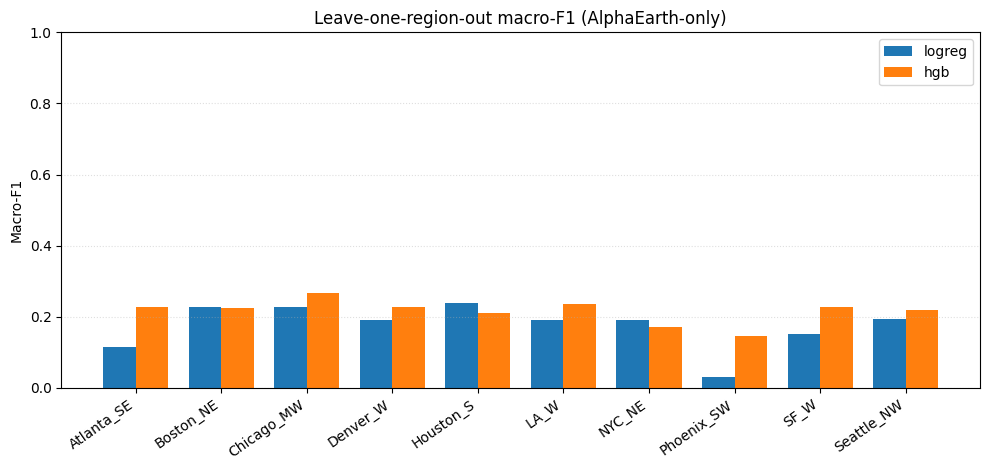

In [20]:
# LORO macro-F1 by region (both models)
fig, ax = plt.subplots(figsize=(10, 4.8))
width = 0.38
x = np.arange(len(region_list))
for i, name in enumerate(MODELS):
    sub = loro[loro["model"] == name].set_index("region").reindex(region_list)
    ax.bar(x + (i - 0.5) * width, sub["f1_macro"], width=width, label=name)
ax.set_xticks(x)
ax.set_xticklabels(region_list, rotation=35, ha="right")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.set_title("Leave-one-region-out macro-F1 (AlphaEarth-only)")
ax.legend()
ax.grid(True, axis="y", linestyle=":", alpha=0.4)
fig.tight_layout()
bar_path = OUT_DIR / "loro_macro_f1_by_region.png"
fig.savefig(bar_path, dpi=150)
print("Saved", bar_path)
plt.show()


### Regional variance

How stable is transfer across metros? Rank regions, summarize spread (mean / std / CV / range),
and plot macro-F1 + accuracy jointly.


In [21]:
# --- Regional variance table ---
region_var_rows = []
for name in MODELS:
    sub = loro[loro["model"] == name].copy()
    mu = sub["f1_macro"].mean()
    sd = sub["f1_macro"].std(ddof=1)
    region_var_rows.append(
        {
            "model": name,
            "n_regions": int(len(sub)),
            "f1_macro_mean": float(mu),
            "f1_macro_std": float(sd),
            "f1_macro_cv": float(sd / mu) if mu > 0 else np.nan,
            "f1_macro_min": float(sub["f1_macro"].min()),
            "f1_macro_max": float(sub["f1_macro"].max()),
            "f1_macro_range": float(sub["f1_macro"].max() - sub["f1_macro"].min()),
            "accuracy_mean": float(sub["accuracy"].mean()),
            "accuracy_std": float(sub["accuracy"].std(ddof=1)),
            "best_region": sub.loc[sub["f1_macro"].idxmax(), "region"],
            "worst_region": sub.loc[sub["f1_macro"].idxmin(), "region"],
        }
    )

region_var = pd.DataFrame(region_var_rows)
region_var_path = OUT_DIR / "loro_region_variance.csv"
region_var.to_csv(region_var_path, index=False)
print("Wrote", region_var_path)
print(region_var.to_string(index=False))

# Ranked region table for best model
best_model = region_var.sort_values("f1_macro_mean", ascending=False).iloc[0]["model"]
ranked = (
    loro[loro["model"] == best_model]
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)
ranked["rank"] = np.arange(1, len(ranked) + 1)
ranked_path = OUT_DIR / f"loro_region_rank_{best_model}.csv"
ranked.to_csv(ranked_path, index=False)
print("\nRanked regions ·", best_model)
print(ranked[["rank", "region", "n_test", "accuracy", "f1_macro", "f1_weighted"]].to_string(index=False))


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_region_variance.csv
 model  n_regions  f1_macro_mean  f1_macro_std  f1_macro_cv  f1_macro_min  f1_macro_max  f1_macro_range  accuracy_mean  accuracy_std best_region worst_region
logreg         10          0.175         0.063        0.357         0.031         0.237           0.206          0.262         0.101   Houston_S   Phoenix_SW
   hgb         10          0.215         0.034        0.157         0.145         0.267           0.122          0.281         0.059  Chicago_MW   Phoenix_SW

Ranked regions · hgb
 rank     region  n_test  accuracy  f1_macro  f1_weighted
    1 Chicago_MW    1321     0.325     0.267        0.303
    2       LA_W    1027     0.300     0.236        0.279
    3   Denver_W    1126     0.315     0.228        0.296
    4 Atlanta_SE    1018     0.269     0.228        0.264
    5       SF_W     805     0.260     0.226        0.244
    6  Boston_NE    1370     0.337     0.224      

Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_region_variance_ranked.png


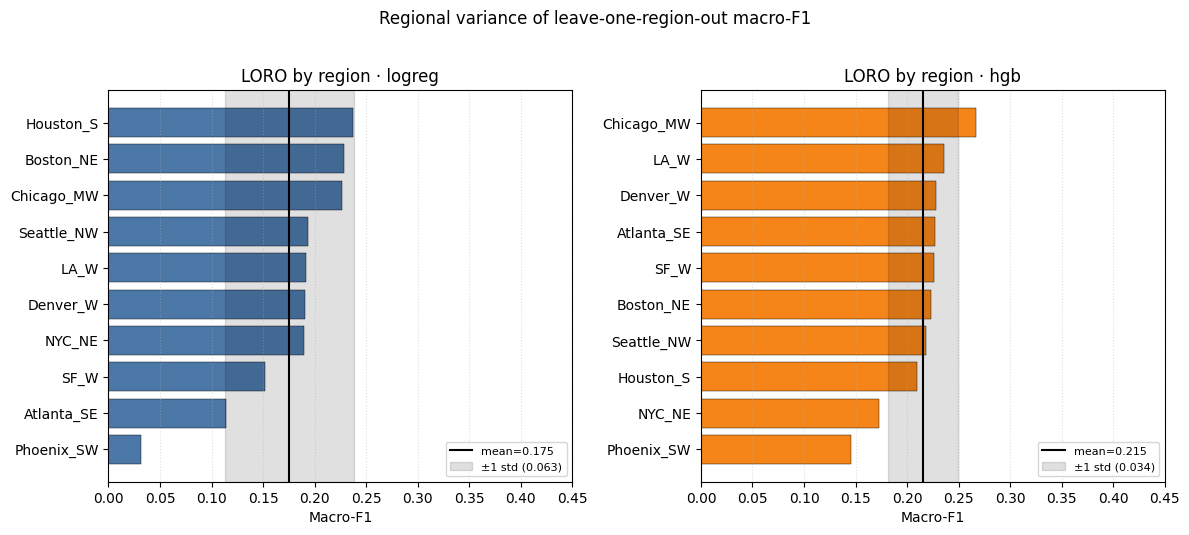

In [22]:
# --- Plot A: ranked horizontal bars + mean/±1 std band ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=False)

for ax, name, color in zip(axes, MODELS, ["#4C78A8", "#F58518"]):
    sub = loro[loro["model"] == name].sort_values("f1_macro", ascending=True)
    mu = sub["f1_macro"].mean()
    sd = sub["f1_macro"].std(ddof=1)
    ax.barh(sub["region"], sub["f1_macro"], color=color, edgecolor="k", linewidth=0.3)
    ax.axvline(mu, color="k", lw=1.5, label=f"mean={mu:.3f}")
    ax.axvspan(mu - sd, mu + sd, color="k", alpha=0.12, label=f"±1 std ({sd:.3f})")
    ax.set_xlim(0, max(0.45, float(sub["f1_macro"].max()) + 0.05))
    ax.set_xlabel("Macro-F1")
    ax.set_title(f"LORO by region · {name}")
    ax.grid(True, axis="x", linestyle=":", alpha=0.4)
    ax.legend(loc="lower right", fontsize=8)

fig.suptitle("Regional variance of leave-one-region-out macro-F1", y=1.02)
fig.tight_layout()
rank_path = OUT_DIR / "loro_region_variance_ranked.png"
fig.savefig(rank_path, dpi=150, bbox_inches="tight")
print("Saved", rank_path)
plt.show()


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_region_variance_cloud_heatmap.png


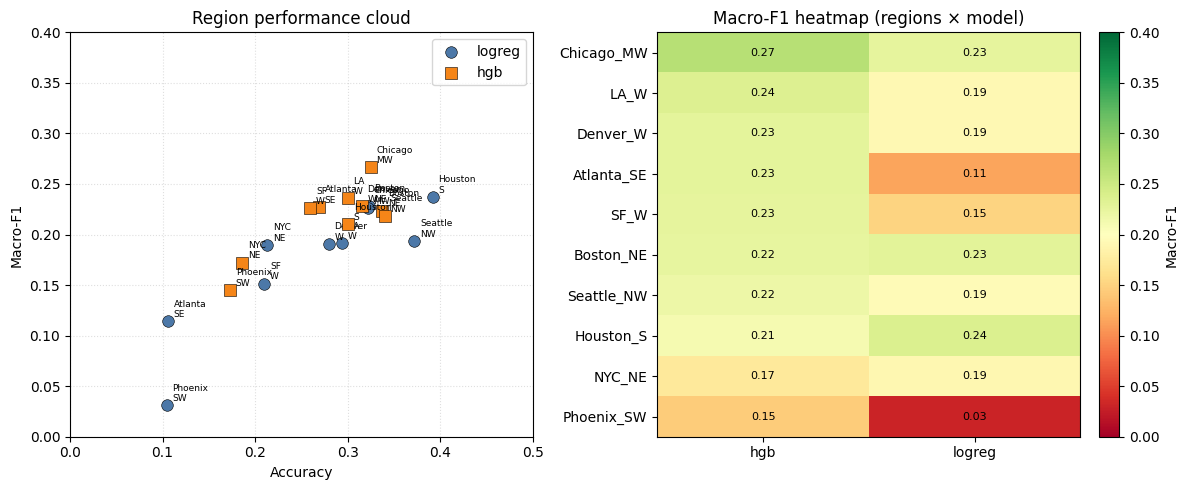

In [23]:
# --- Plot B: scatter accuracy vs macro-F1; heatmap of metrics ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5.0))

ax = axes[0]
for name, marker, color in zip(MODELS, ["o", "s"], ["#4C78A8", "#F58518"]):
    sub = loro[loro["model"] == name]
    ax.scatter(
        sub["accuracy"],
        sub["f1_macro"],
        s=70,
        marker=marker,
        c=color,
        edgecolors="k",
        linewidths=0.4,
        label=name,
        zorder=3,
    )
    for _, r in sub.iterrows():
        ax.annotate(
            r["region"].replace("_", "\n"),
            (r["accuracy"], r["f1_macro"]),
            fontsize=6.5,
            textcoords="offset points",
            xytext=(4, 3),
        )
ax.set_xlabel("Accuracy")
ax.set_ylabel("Macro-F1")
ax.set_title("Region performance cloud")
ax.grid(True, linestyle=":", alpha=0.4)
ax.legend()
ax.set_xlim(0, max(0.5, float(loro["accuracy"].max()) + 0.05))
ax.set_ylim(0, max(0.4, float(loro["f1_macro"].max()) + 0.05))

# Heatmap: regions × (model_metric)
ax = axes[1]
heat = (
    loro.pivot(index="region", columns="model", values="f1_macro")
    .reindex(index=sorted(region_list))
)
# order rows by best-model F1
heat = heat.loc[heat[best_model].sort_values(ascending=False).index]
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="RdYlGn", vmin=0.0, vmax=0.4)
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
ax.set_title("Macro-F1 heatmap (regions × model)")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        val = heat.to_numpy()[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Macro-F1")

fig.tight_layout()
cloud_path = OUT_DIR / "loro_region_variance_cloud_heatmap.png"
fig.savefig(cloud_path, dpi=150)
print("Saved", cloud_path)
plt.show()


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_region_variance_deviation.png


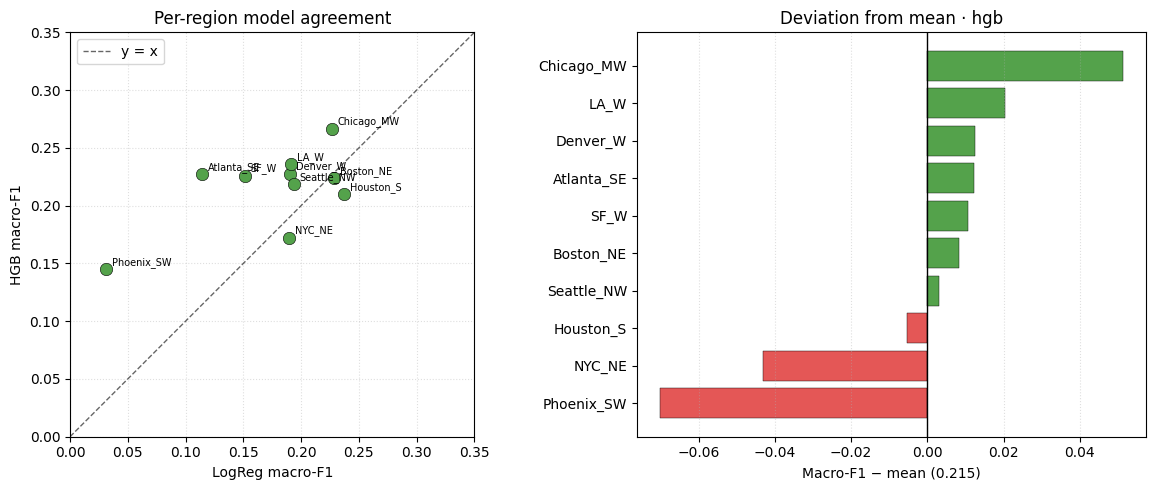

In [24]:
# --- Plot C: paired model comparison + deviation from mean ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5.0))

wide = loro.pivot(index="region", columns="model", values="f1_macro").reindex(region_list)
ax = axes[0]
ax.scatter(wide["logreg"], wide["hgb"], s=80, c="#54A24B", edgecolors="k", linewidths=0.4, zorder=3)
lim_hi = max(0.35, float(wide.max().max()) + 0.05)
ax.plot([0, lim_hi], [0, lim_hi], "k--", lw=1, alpha=0.6, label="y = x")
for reg, row in wide.iterrows():
    ax.annotate(reg, (row["logreg"], row["hgb"]), fontsize=7, textcoords="offset points", xytext=(4, 3))
ax.set_xlabel("LogReg macro-F1")
ax.set_ylabel("HGB macro-F1")
ax.set_title("Per-region model agreement")
ax.set_xlim(0, lim_hi)
ax.set_ylim(0, lim_hi)
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.4)
ax.legend(loc="upper left")

ax = axes[1]
sub = loro[loro["model"] == best_model].copy()
mu = sub["f1_macro"].mean()
sub = sub.sort_values("f1_macro")
colors = ["#E45756" if v < mu else "#54A24B" for v in sub["f1_macro"]]
ax.barh(sub["region"], sub["f1_macro"] - mu, color=colors, edgecolor="k", linewidth=0.3)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel(f"Macro-F1 − mean ({mu:.3f})")
ax.set_title(f"Deviation from mean · {best_model}")
ax.grid(True, axis="x", linestyle=":", alpha=0.4)

fig.tight_layout()
dev_path = OUT_DIR / "loro_region_variance_deviation.png"
fig.savefig(dev_path, dpi=150)
print("Saved", dev_path)
plt.show()


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_us_macro_f1_map.png


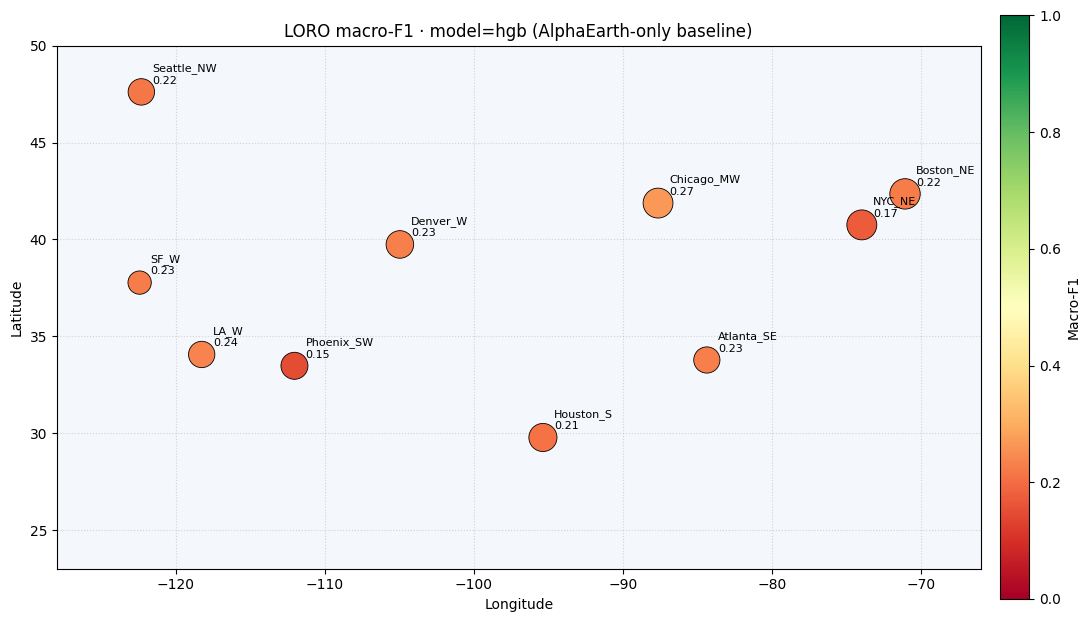

In [25]:
# US bubble map for best LORO model by mean macro-F1
best_model = summary.sort_values("f1_macro_mean", ascending=False).iloc[0]["model"]
map_df = loro[loro["model"] == best_model].copy()

# Region centroids from notebook 04 AOIs (approximate downtown centers)
REGION_XY = {
    "Boston_NE": (-71.075, 42.35),
    "NYC_NE": (-73.975, 40.75),
    "Chicago_MW": (-87.65, 41.875),
    "Atlanta_SE": (-84.375, 33.775),
    "Houston_S": (-95.375, 29.775),
    "Denver_W": (-104.975, 39.74),
    "Phoenix_SW": (-112.05, 33.475),
    "Seattle_NW": (-122.325, 47.615),
    "LA_W": (-118.275, 34.06),
    "SF_W": (-122.44, 37.77),
}
map_df["lon"] = map_df["region"].map(lambda r: REGION_XY[r][0])
map_df["lat"] = map_df["region"].map(lambda r: REGION_XY[r][1])

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.set_xlim(-128, -66)
ax.set_ylim(23, 50)
ax.set_aspect(1.3)
ax.set_facecolor("#f4f7fb")
ax.grid(True, linestyle=":", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"LORO macro-F1 · model={best_model} (AlphaEarth-only baseline)")

sc = ax.scatter(
    map_df["lon"],
    map_df["lat"],
    c=map_df["f1_macro"],
    s=map_df["n_test"] * 0.35,
    cmap="RdYlGn",
    vmin=0.0,
    vmax=1.0,
    edgecolors="k",
    linewidths=0.6,
    zorder=3,
)
cbar = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("Macro-F1")

for _, r in map_df.iterrows():
    ax.annotate(
        f"{r['region']}\n{r['f1_macro']:.2f}",
        (r["lon"], r["lat"]),
        textcoords="offset points",
        xytext=(8, 6),
        fontsize=8,
        ha="left",
    )

fig.tight_layout()
map_path = OUT_DIR / "loro_us_macro_f1_map.png"
fig.savefig(map_path, dpi=150)
print("Saved", map_path)
plt.show()


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_confusion_hgb.png


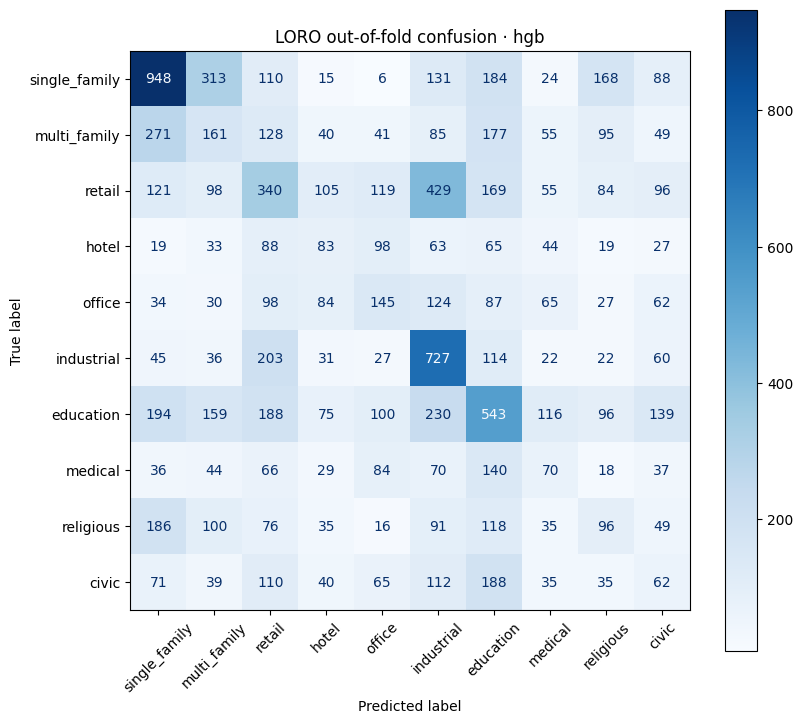

In [26]:
# Confusion matrix from LORO OOF (best model)
pred = oof[best_model]
fig, ax = plt.subplots(figsize=(8.5, 7.5))
ConfusionMatrixDisplay.from_predictions(
    y,
    pred,
    labels=list(range(len(LABEL_ORDER))),
    display_labels=LABEL_ORDER,
    cmap="Blues",
    colorbar=True,
    xticks_rotation=45,
    ax=ax,
    values_format="d",
)
ax.set_title(f"LORO out-of-fold confusion · {best_model}")
fig.tight_layout()
cm_path = OUT_DIR / f"loro_confusion_{best_model}.png"
fig.savefig(cm_path, dpi=150)
print("Saved", cm_path)
plt.show()


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/loro_per_class_f1.png


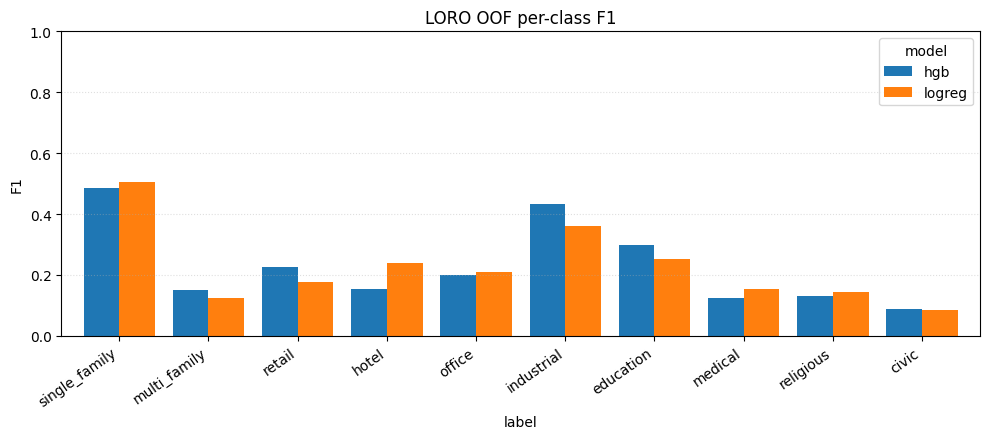

In [27]:
# Per-class F1 bars
pivot = per_class.pivot(index="label", columns="model", values="f1").reindex(LABEL_ORDER)
fig, ax = plt.subplots(figsize=(10, 4.5))
pivot.plot(kind="bar", ax=ax, width=0.8)
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
ax.set_title("LORO OOF per-class F1")
ax.legend(title="model")
ax.grid(True, axis="y", linestyle=":", alpha=0.4)
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
pc_path = OUT_DIR / "loro_per_class_f1.png"
fig.savefig(pc_path, dpi=150)
print("Saved", pc_path)
plt.show()


## 7. Snapshot

Re-state: these numbers are an **AlphaEarth-only US baseline** under locked LORO.
Do not juxtapose them with HeteroGNN 86–96% as if modalities and geographies matched.


In [28]:
metrics_all = pd.concat([pooled, loro], ignore_index=True)
metrics_path = OUT_DIR / "all_metrics.csv"
metrics_all.to_csv(metrics_path, index=False)

snapshot = {
    "protocol": "B_us_alphaearth_only_loro",
    "claim": (
        "AlphaEarth + simple classifier on OSM/Overture high-precision 10-class GT; "
        "not modality-matched to multi-modal SOTA."
    ),
    "data": str(DATA_PATH.relative_to(ROOT)),
    "n_buildings": int(len(df)),
    "n_regions": int(len(region_list)),
    "labels": LABEL_ORDER,
    "regions": region_list,
    "primary_metric": "loro_macro_f1_mean",
    "models": MODELS,
    "best_model_by_loro_macro_f1": best_model,
    "pooled_holdout": pooled.to_dict(orient="records"),
    "loro_summary": summary.to_dict(orient="records"),
    "loro_by_region": loro.to_dict(orient="records"),
    "random_state": RANDOM_STATE,
    "holdout_fraction": HOLDOUT_FRACTION,
    "outputs": sorted(p.name for p in OUT_DIR.iterdir()),
}
snap_path = OUT_DIR / "baseline_snapshot.json"
snap_path.write_text(json.dumps(snapshot, indent=2))
print("Wrote", snap_path)
print(
    json.dumps(
        {
            "best_model": best_model,
            "loro_summary": snapshot["loro_summary"],
            "pooled_holdout": snapshot["pooled_holdout"],
        },
        indent=2,
    )
)


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/us_loro_baseline/baseline_snapshot.json
{
  "best_model": "hgb",
  "loro_summary": [
    {
      "model": "hgb",
      "f1_macro_mean": 0.21533671406372862,
      "f1_macro_std": 0.0339083831547823,
      "accuracy_mean": 0.2805917410297532,
      "accuracy_std": 0.059358956490218724,
      "f1_weighted_mean": 0.25960777351616243
    },
    {
      "model": "logreg",
      "f1_macro_mean": 0.17545563997138247,
      "f1_macro_std": 0.06268385632461447,
      "accuracy_mean": 0.26160396441764844,
      "accuracy_std": 0.10095762086135995,
      "f1_weighted_mean": 0.21106793884984762
    }
  ],
  "pooled_holdout": [
    {
      "protocol": "pooled_holdout",
      "model": "logreg",
      "n_train": 9024,
      "n_test": 2256,
      "accuracy": 0.3891843971631206,
      "f1_macro": 0.3473591217434036,
      "f1_weighted": 0.38509772622408445
    },
    {
      "protocol": "pooled_holdout",
      "model": "hgb",
      "n_trai